<img src='http://drive.google.com/uc?export=view&id=1Lv8NU_SuGQ9uVjU8N6_NwNi72qbSnbQL'>

# <font color='lightblue'>Exploritory Data Analysis</font>

In this project you will perform an exploritory data analysis (EDA) using visualizations and correlations. You may choose from one of the datasets within the [class shared data folder](https://drive.google.com/drive/folders/1s2Civxvys_SR1sFF7D2ept1GSmFbICQb?usp=sharing), or search for a dataset that interests you the most! [Kaggle](https://www.kaggle.com/datasets?fileType=csv) is a good place to start, as they often have relatively clean and easy to use datasets, but feel free to explore other places. There is a lot of data out there!

In this project you will:

1.  Choose and download a dataset
2.  Get summary statistics for key variables
3.  Create visuals to help understand your data
4.  Use correlation to measure relationships between key variables
5.  Summarise how EDA helped (or not!) in understanding your dataset



### This project was completed by:


*   Ahmed Muhammad
*   Joy Umejiego
*   Sandra Igboanugo






Import python libraries


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns


## <font color='lightblue'>1. Data </font>

**Action:** Import your data into colaboratory.


In [ ]:
import kagglehub
import os

path = kagglehub.dataset_download("redwankarimsony/heart-disease-data")

csv_path = os.path.join(path, "heart_disease_uci.csv")
health_data_df = pd.read_csv(csv_path)

health_data_df.head(4)

Using Colab cache for faster access to the 'heart-disease-data' dataset.


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0


In [ ]:
health_data_df.tail(4)

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
916,917,62,Male,VA Long Beach,typical angina,NaN,139.0,False,st-t abnormality,NaN,NaN,NaN,NaN,NaN,NaN,0
917,918,55,Male,VA Long Beach,asymptomatic,122.0,223.0,True,st-t abnormality,100.0,False,0.0,NaN,NaN,fixed defect,2
918,919,58,Male,VA Long Beach,asymptomatic,NaN,385.0,True,lv hypertrophy,NaN,NaN,NaN,NaN,NaN,NaN,0
919,920,62,Male,VA Long Beach,atypical angina,120.0,254.0,False,lv hypertrophy,93.0,True,0.0,NaN,NaN,NaN,1


In [ ]:
health_data_df.isna().shape

(920, 16)

In [ ]:
health_data_df.isna().sum()

,0
id,0
age,0
sex,0
dataset,0
cp,0
trestbps,59
chol,30
fbs,90
restecg,2
thalch,55


From the above code, we can see that there are many variables with quite a sizable null values. The assumption is that some of the origins/datasets maybe as such where they did not record this variable. Running the code to check:

In [ ]:
# Data Cleaning (Impossible values are set to NaN,such as cholestrol being zero)
health_data_df.loc[health_data_df['chol'] == 0, 'chol'] = pd.NA # 0 cholesterol is set to NaN
health_data_df.loc[health_data_df['trestbps'] == 0, 'trestbps'] = pd.NA # 0 resting blood pressure is set to NaN
health_data_df.rename(columns={'dataset': 'origin'}, inplace=True) # changes the column name


Now the data is made up of datasets from 4 'origin' hospitals.

In [ ]:
health_data_df['origin'].value_counts()

,count
origin,
Cleveland,304
Hungary,293
VA Long Beach,200
Switzerland,123


In [ ]:
health_data_df.isna().groupby(health_data_df['origin']).sum()

,id,age,sex,origin,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
origin,,,,,,,,,,,,,,,,
Cleveland,0,0,0,0,0,0,0,0,0,0,0,0,1,5,3,0
Hungary,0,0,0,0,0,1,23,8,1,1,1,0,189,290,265,0
Switzerland,0,0,0,0,0,2,123,75,1,1,1,6,17,118,52,0
VA Long Beach,0,0,0,0,0,57,56,7,0,53,53,56,102,198,166,0


From this, we can see that ca values have only been diligently recorded in Cleaveland. Cholestrol hasnt been recorded in Switzerland and there are alot of 0 values here too for the other origins. Slope values havent been mostly recorded in VA Long Beach and Hungary.

In [ ]:
health_data_df['diseased'] = (health_data_df['num'] != 0).astype(int) # We have converted not 0 (disease as true) and 0 (not diseased as False)
health_data_df.groupby('origin')['diseased'].mean() * 100

,diseased
origin,
Cleveland,45.723684
Hungary,36.177474
Switzerland,93.495935
VA Long Beach,74.500000


This shows that Switzerland had the maximum % of patients coming in with heart problems. This will lead to restriction of range (for us to find the correlation between two variables, they must co-vary). In this case, since most of the population is coming as diseased, we can not accurately determine which other variable varies with num (heart disease or not).

**Action:** Determine the types of data are you dealing with.

In [ ]:
health_data_df.dtypes

,0
id,int64
age,int64
sex,object
origin,object
cp,object
trestbps,float64
chol,float64
fbs,object
restecg,object
thalch,float64


**Continuous numeric:**

**age:** Age in years -> int64

**trestbps:** Resting blood pressure (mm Hg) -> float64

**chol:** Serum cholesterol (mg/dl) -> float64

**thalch:** Max heart rate achieved (bpm) -> float64

**oldpeak:** ST depression induced by exercise -> float64

**Discrete/ordinal numeric:**

**ca:**	Number of major vessels colored by fluoroscopy (0, 1, 2, 3) -> float64 (stored as float due to NaNs, but really an ordinal count)

**num:** *converted to 0 and 1* Disease severity/presence (0 = none, 1 = increasing severity combined) -> int64

**Nominal categorical:**

**id:** Unique id for each patient

**sex:** *coverted to 1 as male and 0 as Female for correlation* Male / Female

**origin:** Study site/origin (Cleveland, Hungary, Switzerland, VA Long Beach)

**cp:** Chest pain type	(typical angina, atypical angina, non-anginal, asymptomatic)

**fbs:** *coverted to 0 and 1* fasting blood sugar > 120 mg/dl (True/False)

**restecg:** Resting ECG results (normal, st-t abnormality, lv hypertrophy)

**exang:** exercise-induced angina (True/False)

**thal:** Thalassemia/thallium test result (normal, fixed defect, reversable defect)

**Ordinal categorical:**

**slope:** Slope of peak exercise ST segment (upsloping, flat, downsloping)

## <font color='lightblue'>2. Summary statistics</font>

**Action:** Estimate the summary statistics of some of the key variables

In [ ]:
key_vars = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']

summary = health_data_df[key_vars].describe().round(2)

# Add extra useful stats: missing count, skewness
summary.loc['missing'] = health_data_df[key_vars].isnull().sum()
summary.loc['skew'] = health_data_df[key_vars].skew().round(2)

print(summary)

            age  trestbps    chol  thalch  oldpeak
count    920.00    860.00  718.00  865.00   858.00
mean      53.51    132.29  246.83  137.55     0.88
std        9.42     18.54   58.53   25.93     1.09
min       28.00     80.00   85.00   60.00    -2.60
25%       47.00    120.00  210.00  120.00     0.00
50%       54.00    130.00  239.50  140.00     0.50
75%       60.00    140.00  276.75  157.00     1.50
max       77.00    200.00  603.00  202.00     6.20
missing    0.00     60.00  202.00   55.00    62.00
skew      -0.20      0.63    1.31   -0.21     1.04


In [ ]:
health_data_df.describe().round(2)

,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.00,920.00,860.00,718.00,865.00,858.00,309.00,920.00
mean,460.50,53.51,132.29,246.83,137.55,0.88,0.68,1.00
std,265.73,9.42,18.54,58.53,25.93,1.09,0.94,1.14
min,1.00,28.00,80.00,85.00,60.00,-2.60,0.00,0.00
25%,230.75,47.00,120.00,210.00,120.00,0.00,0.00,0.00
50%,460.50,54.00,130.00,239.50,140.00,0.50,0.00,1.00
75%,690.25,60.00,140.00,276.75,157.00,1.50,1.00,2.00
max,920.00,77.00,200.00,603.00,202.00,6.20,3.00,4.00


## <font color='lightblue'>3. Visualize the data</font>

**Action:** Visualize the distribution of values for some key variables

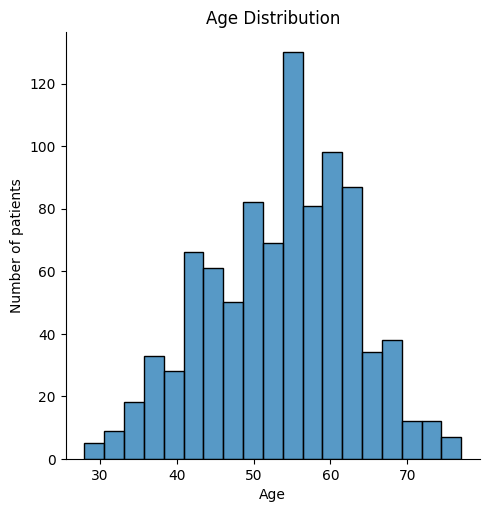

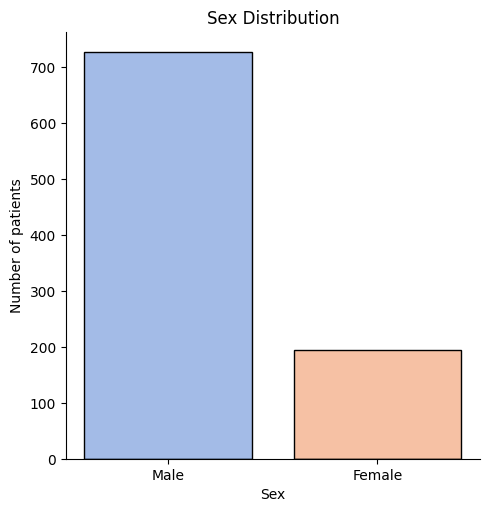

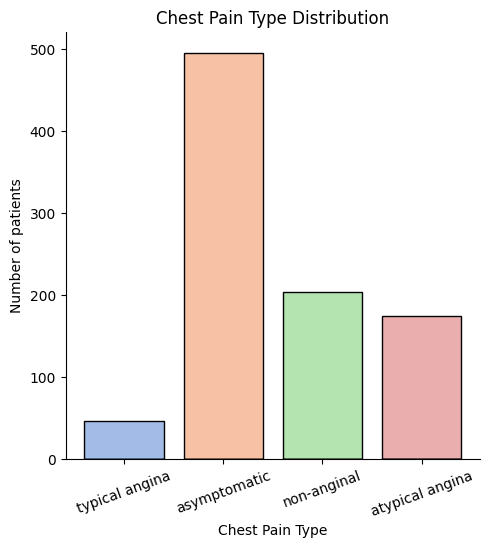

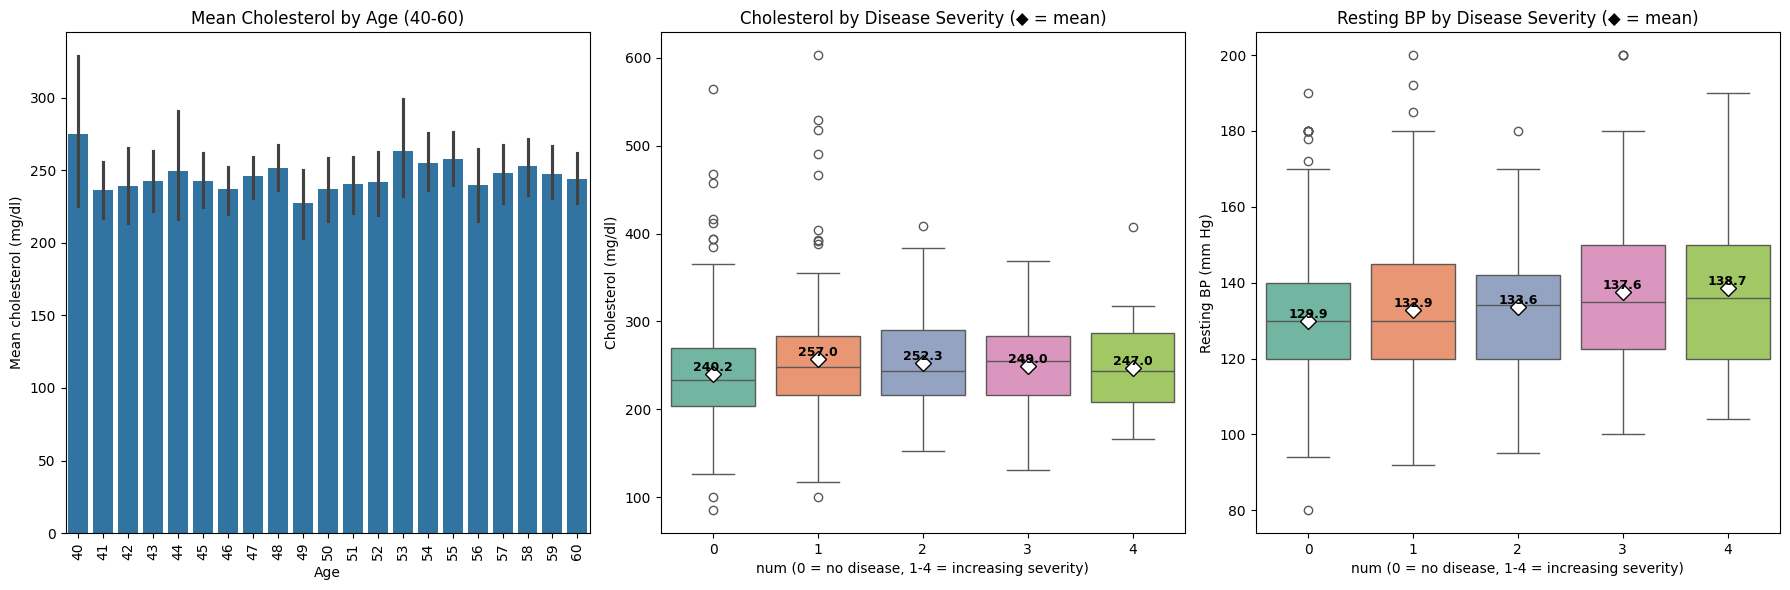

In [ ]:
age_filtered = health_data_df[(health_data_df['age']>=40) & (health_data_df['age']<=60)]

sns.displot(data=health_data_df, x='age')
plt.xlabel('Age')
plt.ylabel('Number of patients')
plt.title('Age Distribution')
plt.show()

sns.displot(data=health_data_df, x='sex', hue='sex', palette='muted', legend=False, shrink=0.8)
plt.xlabel('Sex')
plt.ylabel('Number of patients')
plt.title('Sex Distribution')
plt.show()


sns.displot(data=health_data_df, x='cp', hue='cp', palette='muted', legend=False, shrink=0.8)
plt.xlabel('Chest Pain Type')
plt.ylabel('Number of patients')
plt.title('Chest Pain Type Distribution')
plt.xticks(rotation=20)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

sns.barplot(data=age_filtered, x='age', y='chol', ax=axes[0])
axes[0].set_ylabel('Mean cholesterol (mg/dl)')
axes[0].set_xlabel('Age')
axes[0].set_title('Mean Cholesterol by Age (40-60)')
axes[0].tick_params(axis='x', rotation=90)


sns.boxplot(data=health_data_df, x='num', y='chol', hue='num', legend=False, palette='Set2', ax=axes[1],
            showmeans=True,
            meanprops={"marker":"D", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"8"})
axes[1].set_xlabel('num (0 = no disease, 1-4 = increasing severity)')
axes[1].set_ylabel('Cholesterol (mg/dl)')
axes[1].set_title('Cholesterol by Disease Severity (◆ = mean)')

means_chol = health_data_df.groupby('num')['chol'].mean()
for i, mean_val in enumerate(means_chol):
    axes[1].text(i, mean_val, f'{mean_val:.1f}',
                 ha='center', va='bottom', fontsize=9, fontweight='bold', color='black')

sns.boxplot(data=health_data_df, x='num', y='trestbps', hue='num', legend=False, palette='Set2', ax=axes[2],
            showmeans=True,
            meanprops={"marker":"D", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"8"})
axes[2].set_xlabel('num (0 = no disease, 1-4 = increasing severity)')
axes[2].set_ylabel('Resting BP (mm Hg)')
axes[2].set_title('Resting BP by Disease Severity (◆ = mean)')

means_trest = health_data_df.groupby('num')['trestbps'].mean()
for i, mean_val in enumerate(means_trest):
    axes[2].text(i, mean_val, f'{mean_val:.1f}',
                 ha='center', va='bottom', fontsize=9, fontweight='bold', color='black')

plt.tight_layout()
plt.show()

**Q1:** Explain your choice of plots using the five visualization components:
1. Data component -- what kinds of data are you dealing with?
2. Graphical component -- what kinds of plot can you use?
3. Label component -- what should be on the plot axis?
4. Esthetic component -- what should you plot say, and how best to do this?
5. Ethical component -- Is the graph misleading, what is left out?

**1. Data component:**
Two different data types are being visualized.

- **Continuous numeric (age, trestbps, chol, thalch, oldpeak):** A real-valued measurements with meaningful spacing between values.

- **Categorical / nominal (cp, sex, exang):** discrete labels or groups with no inherent numeric spacing.

- **Discrete/ordinal numeric (num):** stored as numbers but represents ordered severity levels (0 = none → 4 = most severe), not a continuous scale.

**2. Graphical Component:**

- **Histogram** for continuous variables (age): it bins the range into intervals and shows frequency per bin, which reveals shape, spread, and outliers all at once.

- **Bar chart** for categorical variables: one bar per category, height = count. There's no ordering/binning issue since categories are discrete and unordered (for sex, cp) or naturally so few that a bar chart reads instantly.

- **Boxplot** for a continuous variable split by an ordinal group (chol/trestbps by num) which summarizes each severity group's median, IQR, and outliers side-by-side, which reveals whether the distribution shifts across groups. A scatterplot can't do this cleanly when the x-variable only has 5 discrete values.

**3. Label Component**

- Y-axis units are matched to what each plot type actually measures: "Number of patients" for the count-based plots (histogram and bar charts), and the relevant clinical unit ("Mean cholesterol (mg/dl)", "Cholesterol (mg/dl)", "Resting BP (mm Hg)") for the barplot and boxplots, since those show a value's distribution or average rather than a frequency count.

- X-axis labels differ by variable type: **continuous variables** (trestbps, chol) get their unit substituted entirely (e.g. "Resting BP (mm Hg)"), since the unit alone is meaningful. The **target variable** *num* keeps its column name paired with its coding explained inline ("num (0 = no disease, 1-4 = increasing severity)"), since it's a study-assigned scale without a real-world unit, so naming it directly is more precise than inventing a substitute label.

**4. Esthetic Component**

- *"shrink=0.8"* on the sex and cp displots adds visible gaps between bars, which helps distinguish discrete categories from a continuous histogram at a glance. Without it, categorical bars can visually blend into the axis and look like a binned continuous variable.

- Restricting the age-vs-cholesterol barplot to ages 40-60 (age_filtered) keeps the x-axis legible, plotting all ~50 individual ages as separate bars would produce a cluttered, unreadable strip of thin bars, so the filter trades completeness for clarity, provided the filter itself is disclosed.

- The two boxplots use the same x-variable (num) side by side, which lets a reader visually compare how strongly cholesterol vs. blood pressure track with severity just by comparing how much the boxes shift left-to-right across the two figures.

**5. Ethical Component**

- Missing data is invisible in these plots. Variable
'chol' has 202 missing values, thalch has 55, exang has 55, etc. The histograms only show what exists, silently excluding NaNs. A viewer could reasonably assume the full 920 patients are represented in every panel; they aren't. Worth adding an annotation like "n=718" if this goes into a report.

- Sex is heavily imbalanced (79% male). This histogram accurately reflects the sample, but a viewer could mistakenly generalize it as reflecting heart disease prevalence by sex in the real population. It only reflects who happened to be in this clinical study, likely due to referral patterns at the original hospitals, not the true population split.

- The age_filtered barplot silently drops every patient under 40 or over 60. That's a real chunk of your 920 patients excluded from that one chart without any on-chart indication. If this plot is shown standalone in a report, a viewer could easily assume it represents the full age range in the dataset rather than a 20-year slice chosen for readability.

## <font color='lightblue'>4. Correlations</font>

**Action:** Use correlation to estimate the relationship between some of the key variables. Try exploring for interesting relationships using heatmaps.

In [ ]:
numeric_cols = ['age','sex','trestbps','chol','fbs','thalch','exang','oldpeak','ca','num']
categorical_cols = ['sex','fbs','exang','origin','cp','restecg','slope','ca','thal','num']

In [ ]:
corr_matrix = (
    health_data_df[numeric_cols]
    .assign(sex=health_data_df['sex'].replace({'Male': 1, 'Female': 0}))
    .corr(method='spearman')
)

/tmp/ipykernel_2794/2215525132.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .assign(sex=health_data_df['sex'].replace({'Male': 1, 'Female': 0}))


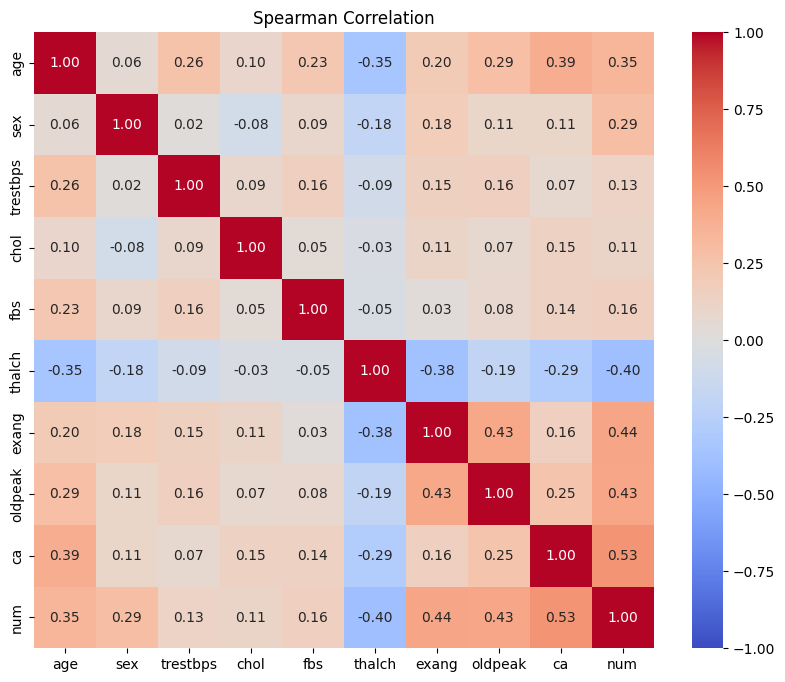

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Spearman Correlation")
plt.show()



*Bivariable **categorical** data such as Sex (Male=1 and Female=0), fasting blood sugar (fbs)>120, exang all converted to 0 and 1 for correlation in the heat graph. Number of major Arteries coloured by floroscopy (ca) is also 4 categories but ANOVA was not run, it was kept in the heatmap to ascertain any link to heart disease (num) or no*

**Q2:** Choose one or two correlations and describe what the magnitude and direction of the correlation suggests about the relationship between the two variables.

**ca and num (r ≈ 0.53):** As the number of major vessels showing blockage (ca) increases, disease severity (num) tends to increase as well, which is a moderate or a little strong positive relationship. This matches clinical expectations, since more vessels affected on imaging should reasonably track with worse cardiac outcomes.

**thalch and num (r ≈ -0.40):** As maximum heart rate achieved during exercise (thalch) decreases, disease severity tends to increase, which is a moderate negative relationship. This aligns with the concept of chronotropic incompetence, where more diseased hearts often can't raise their rate as much under exertion.


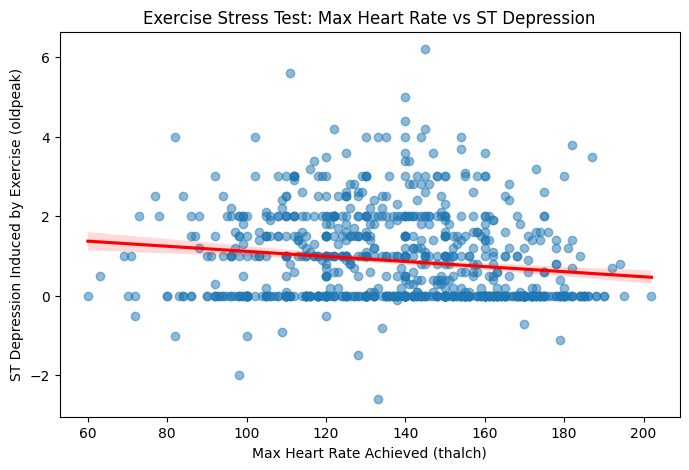

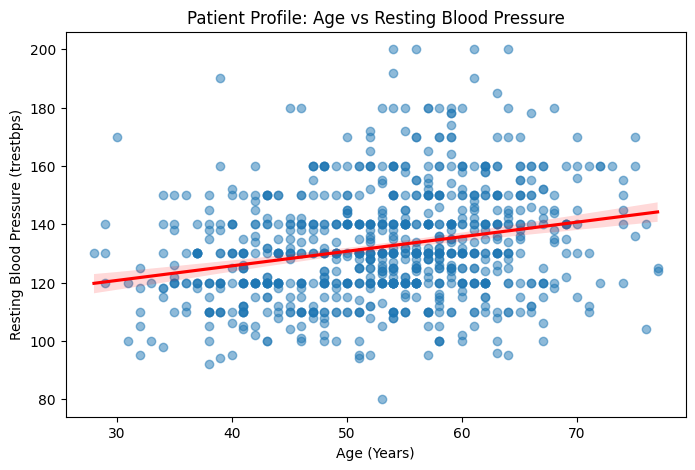

In [ ]:

# Create a new figure and set its size (8 inches wide by 5 inches tall)
plt.figure(figsize=(8, 5))

# Create a scatterplot with a linear regression (trend) line
sns.regplot(
    data=health_data_df,            # The dataframe containing our cleaned data
    x='thalch',                     # X-axis: Maximum heart rate achieved (continuous)
    y='oldpeak',                    # Y-axis: ST depression induced by exercise (continuous)
    scatter_kws={'alpha': 0.5},     # Makes the raw data dots 50% transparent to show overlapping density
    line_kws={'color': 'red'}       # Colors the mathematical trend line red so it stands out
)

# Add a clear, descriptive title to the top of the plot
plt.title('Exercise Stress Test: Max Heart Rate vs ST Depression')

# Label the X and Y axes with both the clinical description and the column name
plt.xlabel('Max Heart Rate Achieved (thalch)')
plt.ylabel('ST Depression Induced by Exercise (oldpeak)')

# Display the final plot cleanly without any extra text output above it
plt.show()

plt.figure(figsize=(8, 5))

# Create a scatterplot for Age vs Resting Blood Pressure
sns.regplot(
    data=health_data_df,
    x='age',
    y='trestbps',
    scatter_kws={'alpha': 0.5},
    line_kws={'color': 'red'}
)

plt.title('Patient Profile: Age vs Resting Blood Pressure')
plt.xlabel('Age (Years)')
plt.ylabel('Resting Blood Pressure (trestbps)')

plt.show()

**thalch and oldpeak (r ≈ -0.19):** As demonstrated by the downward-sloping trend line in the scatterplot, when maximum heart rate achieved during exercise (thalch) increases, exercise-induced ST depression (oldpeak) tends to decrease. This weak negative correlation aligns with clinical expectations, as healthier hearts can reach higher rates under physical exertion without showing signs of ischemic stress.

**age and trestbps (r ≈ 0.26):** As demonstrated by the upward-sloping trend line in the scatterplot, as a patient's age increases, their resting blood pressure (trestbps) tends to increase as well. This weak-to-moderate positive correlation aligns with standard clinical expectations, as blood vessels naturally stiffen over time, leading to higher resting blood pressure in older demographics.


## <font color='lightblue'>5. Discussion</font>

**Q3:** Did this exploritory data analysis help you better understand your chosen dataset? If so how? Is there still parts that don't make sense?
> The idea with this question is not to see if you know everything about this dataset, just how EDA might have helped (or not!).

**Answer:**

Yes, in several ways that weren't obvious just from reading the column descriptions.

172 patients showed chol = 0, which is medically impossible. That's a placeholder for missing data, not a real reading. Without checking distributions and physiological plausibility directly, I'd have taken those zeros at face value and badly understated average cholesterol.

Also the variables I assumed would be the strongest indicators weren't. I expected cholesterol and resting blood pressure to be the headline heart disease indicators since that's the popular narrative. Instead, correlation and boxplots showed chol and trestbps barely tracked with disease severity.

Furthermore, plot choice actually changes what you can see. The clearest example was chol vs num: a scatterplot just showed five overlapping vertical stripes and told me almost nothing, while a boxplot of the same two variables immediately showed the trend. Same data, very different amount of insight depending on the visualization.